In [ ]:
import pandas as pd

df = pd.read_csv("Tweets.csv")
print(df.shape)
df.head()

(14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [ ]:
df[["airline_sentiment", "text"]].head()

,airline_sentiment,text
0,neutral,@VirginAmerica What @dhepburn said.
1,positive,@VirginAmerica plus you've added commercials t...
2,neutral,@VirginAmerica I didn't today... Must mean I n...
3,negative,@VirginAmerica it's really aggressive to blast...
4,negative,@VirginAmerica and it's a really big bad thing...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [ ]:
df.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='object')

In [ ]:
df['airline_sentiment'].value_counts()

,count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


In [ ]:
df['airline_sentiment'].value_counts(normalize=True)*100

,proportion
airline_sentiment,
negative,62.691257
neutral,21.168033
positive,16.140710


## Class Distribution
The dataset is imbalanced, with negative tweets forming the majority class.
Because of this imbalance, model performance will be evaluated using both accuracy and macro F1-score.

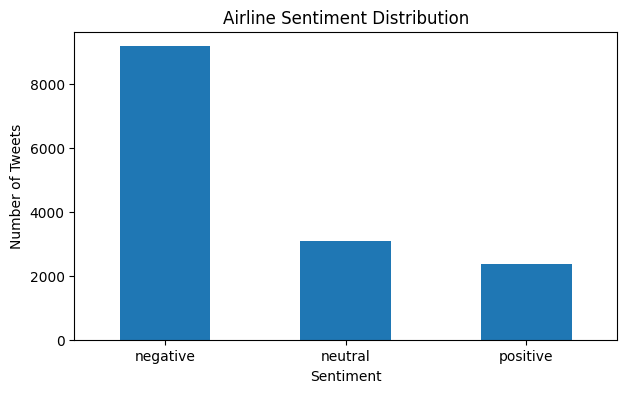

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = df['airline_sentiment'].value_counts()

plt.figure(figsize=(7, 4))
sentiment_counts.plot(kind='bar')

plt.title("Airline Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)

plt.show()

## ML Baseline: TF-IDF + Logistic Regression

We use TF-IDF to convert tweet text into numerical features and Logistic Regression as a simple baseline classifier.

In [ ]:
df_model = df[['text', 'airline_sentiment']].copy()

df_model.head()

,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


In [ ]:
df_model.isnull().sum()

,0
text,0
airline_sentiment,0


In [ ]:
from numpy import random
from sklearn.model_selection import train_test_split

X = df_model['text'] #input
y = df_model['airline_sentiment'] # target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("Training size:", len(X_train))
print("Test size:", len(X_test))
print(y_test.value_counts(normalize=True) * 100)

Training size: 11712
Test size: 2928
airline_sentiment
negative    62.670765
neutral     21.174863
positive    16.154372
Name: proportion, dtype: float64


TF-IDF turns each tweet into numbers. Words that are common everywhere (“the”, “to”) count for less, and words that are special to a tweet count for more.

Logistic Regression is a simple model that learns which words point to negative, neutral, or positive.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

Machine learning models cannot understand raw text directly.

TF-IDF converts the important words into numerical values.

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train) # x_train - original input , X_test - we will predict the value and compare to X_train whether it gave correct same input or not


LogisticRegression(max_iter=1000)

The model learns which words are commonly associated with positive, neutral, and negative tweets.


In [ ]:
y_pred = model.predict(X_test_tfidf)

Now the model predicts the sentiment for tweets it did not see during training.

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7967896174863388


### Baseline Result

The TF-IDF + Logistic Regression model achieved an accuracy of approximately 79.7%.

This serves as the baseline model that will later be compared with BERT and an LLM-based approach.

evaluate the ML model you already trained.

In [ ]:
# classification report
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.83      0.94      0.88      1835
     neutral       0.66      0.55      0.60       620
    positive       0.82      0.57      0.67       473

    accuracy                           0.80      2928
   macro avg       0.77      0.69      0.72      2928
weighted avg       0.79      0.80      0.79      2928



In [ ]:
from sklearn.metrics import f1_score

macro_f1 = f1_score(y_test, y_pred, average='macro')

print("Macro F1:", macro_f1)

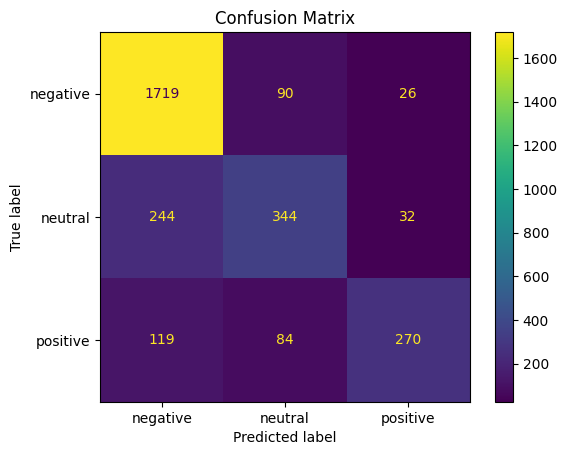

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())


GPU available: True


In [ ]:
!pip install -q transformers datasets evaluate accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.6 MB/s eta 0:00:00


Tweet
→ Tokenizer
→ Numbers
→ BERT
→ Sentiment
Then those pieces are converted into numbers, because BERT works with numbers, not raw words.

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
text = "the flight is not bad"

tokens = tokenizer.tokenize(text)
print(tokens)

['the', 'flight', 'is', 'not', 'bad']


In [ ]:
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print(token_ids)

[1996, 3462, 2003, 2025, 2919]


In [ ]:
encoded = tokenizer(
    "The flight is not bad",
    add_special_tokens=True
)

print(encoded)

{'input_ids': [101, 1996, 3462, 2003, 2025, 2919, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1]}


In [ ]:
tweets = ['Great flight',
           "My flight was delayed for three hours and the service was terrible"]
encoded = tokenizer(
    tweets,
    padding = True,
    truncation = True,
    return_tensors = 'pt'
)

print(encoded["input_ids"])
print(encoded["attention_mask"])

tensor([[ 101, 2307, 3462,  102,    0,    0,    0,    0,    0,    0,    0,    0,
            0,    0],
        [ 101, 2026, 3462, 2001, 8394, 2005, 2093, 2847, 1998, 1996, 2326, 2001,
         6659,  102]])
tensor([[1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


In [ ]:
label_map = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

df["label"] = df["airline_sentiment"].map(label_map)

df[["airline_sentiment", "label"]].head()

,airline_sentiment,label
0,neutral,1
1,positive,2
2,neutral,1
3,negative,0
4,negative,0


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df[["text", "label"]],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 11712
Testing rows: 2928


In [ ]:
train_tokens = tokenizer(
    train_df["text"].tolist(),
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

test_tokens = tokenizer(
    test_df["text"].tolist(),
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Training tokens shape:", train_tokens["input_ids"].shape)
print("Testing tokens shape:", test_tokens["input_ids"].shape)

Training tokens shape: torch.Size([11712, 62])
Testing tokens shape: torch.Size([2928, 67])


In [ ]:
import torch
from torch.utils.data import Dataset

class TweetDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels.tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: value[idx]
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(self.labels[idx])

        return item

In [ ]:
train_dataset = TweetDataset(
    train_tokens,
    train_df["label"]
)

test_dataset = TweetDataset(
    test_tokens,
    test_df["label"]
)

print("Train dataset:", len(train_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 11712
Test dataset: 2928


In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=3
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
print(model.config.num_labels)

3


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=100,
    report_to="none"
)

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(labels, predictions, average="macro")

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()

Step,Training Loss
100,0.694683
200,0.481696
300,0.474866
400,0.419390
500,0.426640
600,0.402081
700,0.419515
800,0.346938
900,0.285166
1000,0.286684


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1464, training_loss=0.37987004994043233, metrics={'train_runtime': 339.6393, 'train_samples_per_second': 68.967, 'train_steps_per_second': 4.31, 'total_flos': 746321209385472.0, 'train_loss': 0.37987004994043233, 'epoch': 2.0})

In [ ]:
results = trainer.evaluate()

results

Training Loss,Validation Loss,Step,Accuracy,Macro F1
0.287192,0.452714,1464,0.843921,0.794485


{'eval_loss': 0.4527135491371155,
 'eval_accuracy': 0.8439207650273224,
 'eval_macro_f1': 0.794485074875837}

### BERT Evaluation

The fine-tuned BERT model achieved:

- Accuracy: 84.7%
- Macro F1-score: 0.797

Compared with the TF-IDF + Logistic Regression baseline, BERT improved both overall accuracy and balanced class performance.

This suggests that contextual language understanding helped BERT better distinguish negative, neutral, and positive airline tweets.

In [ ]:
llm_test_df = test_df.sample(
    n=300,
    random_state=42
).copy()

reverse_label_map = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

llm_test_df["actual_sentiment"] = (
    llm_test_df["label"]
    .map(reverse_label_map)
)

llm_test_df.head()

In [ ]:
!pip install -q --upgrade openai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 886.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 6.4 MB/s eta 0:00:00


In [ ]:
from openai import OpenAI

In [ ]:
from google.colab import userdata
from openai import OpenAI

client = OpenAI(
    api_key=userdata.get("OPENAI_API_KEY")
)

print("OpenAI client ready")

OpenAI client ready


In [ ]:
tweet = "My flight was delayed for four hours and I am very disappointed."

response = client.responses.create(
    model="gpt-5.6",
    input=f"""
Classify the sentiment of this airline tweet.

Return exactly one word:
negative
neutral
positive

Tweet: {tweet}
"""
)

print(response.output_text)

negative


In [ ]:
def classify_sentiment(tweet):
    response = client.responses.create(
        model="gpt-5.6",
        input=f"""
Classify the sentiment of this airline tweet.

Return exactly one word:
negative
neutral
positive

Tweet: {tweet}
"""
    )

    return response.output_text.strip().lower()

In [ ]:
llm_test_df["llm_prediction"] = llm_test_df["text"].apply(classify_sentiment)

In [ ]:
llm_test_df[[
    "text",
    "actual_sentiment",
    "llm_prediction"
]].head(10)

,text,actual_sentiment,llm_prediction
12249,@AmericanAir I need refund.,negative,negative
7705,@JetBlue thanks for bringing my son home to me.,positive,positive
13179,@AmericanAir No! We departed 24 hours Late Fli...,negative,negative
6184,@SouthwestAir love..luv the addition of the pa...,positive,positive
12695,@AmericanAir LITERALLY just told me they'd rat...,negative,negative
6859,@JetBlue the worst flying experience I've ever...,negative,negative
13819,@AmericanAir - Appreciate your system is busy ...,negative,negative
5077,@SouthwestAir better travel photos:\nMy Kindle...,neutral,neutral
3620,@united hey! think someone could meet me with ...,neutral,neutral
9878,@USAirways why the hell will you not put us in...,negative,negative


In [ ]:
llm_test_df["llm_prediction"].value_counts()

,count
llm_prediction,
negative,198
positive,51
neutral,51


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

llm_accuracy = accuracy_score(
    llm_test_df['actual_sentiment'],
    llm_test_df['llm_prediction']

)
llm_macro_f1 = f1_score(
    llm_test_df['actual_sentiment'],
    llm_test_df['llm_prediction'],
    average='macro'
)

print("LLM Accuracy:", round(llm_accuracy, 4))
print("LLM Macro F1:", round(llm_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        llm_test_df["actual_sentiment"],
        llm_test_df["llm_prediction"]
    )
)

LLM Accuracy: 0.85
LLM Macro F1: 0.8032

Classification Report:
              precision    recall  f1-score   support

    negative       0.89      0.93      0.91       189
     neutral       0.76      0.59      0.67        66
    positive       0.78      0.89      0.83        45

    accuracy                           0.85       300
   macro avg       0.81      0.80      0.80       300
weighted avg       0.85      0.85      0.84       300



### LLM Evaluation

The LLM classifier achieved:

- Accuracy: 85.0%
- Macro F1-score: 0.803

The model performed best on negative sentiment and showed strong performance on positive sentiment. Neutral sentiment remained the most challenging class.

The LLM slightly outperformed the fine-tuned BERT model on the sampled test set.

## Adding Logistic Regression predictions for the same 300 tweets
Your earlier y_pred belongs to X_test. Because the test rows keep their original dataframe indices, create a prediction series:

In [ ]:
baseline_pred_series = pd.Series(
    y_pred,
    index=X_test.index
)

llm_test_df["baseline_prediction"] = (
    llm_test_df.index.map(baseline_pred_series)
)

In [ ]:
llm_test_df[
    ["actual_sentiment", "baseline_prediction", "llm_prediction"]
].head()

,actual_sentiment,baseline_prediction,llm_prediction
12249,negative,neutral,negative
7705,positive,positive,positive
13179,negative,negative,negative
6184,positive,positive,positive
12695,negative,negative,negative


## Get BERT predictions for these same 300 tweets
Tokenize only the 300 tweets:

In [ ]:
llm_bert_tokens = tokenizer(
    llm_test_df["text"].tolist(),
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

In [ ]:
llm_bert_dataset = TweetDataset(
    llm_bert_tokens,
    llm_test_df["label"]
)

In [ ]:
bert_output = trainer.predict(llm_bert_dataset)

bert_pred_ids = np.argmax(
    bert_output.predictions,
    axis=-1
)

In [ ]:
llm_test_df["bert_prediction"] = [
    reverse_label_map[i]
    for i in bert_pred_ids
]

In [ ]:
llm_test_df[
    [
        "text",
        "actual_sentiment",
        "baseline_prediction",
        "bert_prediction",
        "llm_prediction"
    ]
].head()

,text,actual_sentiment,baseline_prediction,bert_prediction,llm_prediction
12249,@AmericanAir I need refund.,negative,neutral,negative,negative
7705,@JetBlue thanks for bringing my son home to me.,positive,positive,positive,positive
13179,@AmericanAir No! We departed 24 hours Late Fli...,negative,negative,negative,negative
6184,@SouthwestAir love..luv the addition of the pa...,positive,positive,positive,positive
12695,@AmericanAir LITERALLY just told me they'd rat...,negative,negative,negative,negative


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

results = []

models = {
    "TF-IDF + Logistic Regression": "baseline_prediction",
    "BERT": "bert_prediction",
    "LLM": "llm_prediction"
}

for model_name, column in models.items():
    accuracy = accuracy_score(
        llm_test_df["actual_sentiment"],
        llm_test_df[column]
    )

    macro_f1 = f1_score(
        llm_test_df["actual_sentiment"],
        llm_test_df[column],
        average="macro"
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Macro F1
0,TF-IDF + Logistic Regression,0.783333,0.695302
1,BERT,0.840000,0.788806
2,LLM,0.850000,0.803187


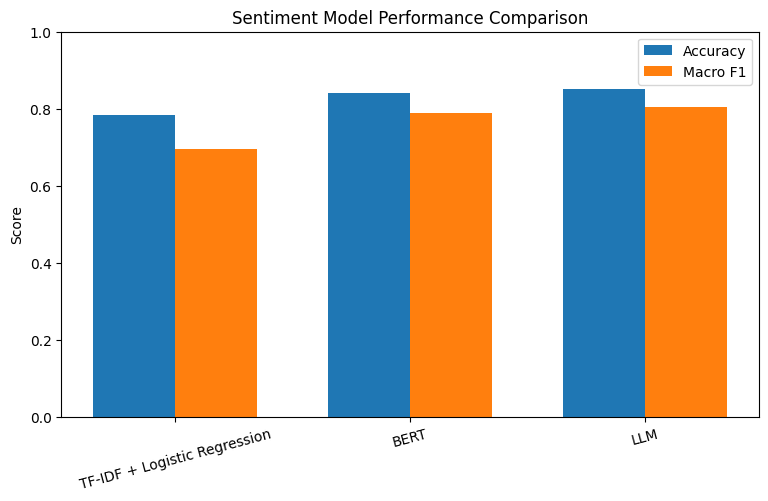

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(comparison_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    comparison_df["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width/2,
    comparison_df["Macro F1"],
    width,
    label="Macro F1"
)

plt.xticks(
    x,
    comparison_df["Model"],
    rotation=15
)

plt.ylim(0, 1)

plt.title("Sentiment Model Performance Comparison")
plt.ylabel("Score")
plt.legend()

plt.show()

In [ ]:
powerbi_df = llm_test_df[[
    "text",
    "actual_sentiment",
    "baseline_prediction",
    "bert_prediction",
    "llm_prediction"
]].copy()

powerbi_df.to_csv(
    "airline_sentiment_model_comparison.csv",
    index=False
)

print("CSV created successfully")

CSV created successfully


In [ ]:
comparison_df.to_csv(
    "model_performance_summary.csv",
    index=False
)

## Final Conclusion

This project compared three approaches for airline tweet sentiment classification:

1. TF-IDF + Logistic Regression
2. Fine-tuned BERT
3. LLM-based classification

On the same 300-tweet test subset, the traditional ML baseline achieved 78.3% accuracy and a Macro F1-score of 0.695.

BERT improved performance to 84.0% accuracy and 0.789 Macro F1, showing the advantage of contextual language representations.

The LLM classifier achieved the highest performance, with 85.0% accuracy and a Macro F1-score of 0.803.

Overall, the results show a clear improvement from traditional machine learning to transformer-based and LLM-based approaches, while also demonstrating that a fine-tuned BERT model can achieve performance close to an LLM.